# Tugas Besar 2 IF3170: Prediksi Pembatalan Pemesanan Penginapan

# Initialization

## Import Libraries

In [1]:
import os
import pickle
import random
import time

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Kode From Scratch

In [2]:
# utils: save/load model, metric evaluasi, dan cross validation

# simpan model ke file pickle
def save_model(model, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'wb') as f:
        pickle.dump(model, f)

# load lagi model yang disimpan pakai save_model
def load_model(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

# confusion matrix biner, bentuknya [[TN, FP], [FN, TP]]
def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1))); tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1))); fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return np.array([[tn, fp], [fn, tp]])

# F1 buat class 0 dan class 1, hasilnya [f1_0, f1_1]
def f1_per_class(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    f1_pos = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn > 0 else 0.0
    f1_neg = 2 * tn / (2 * tn + fn + fp) if tn + fn + fp > 0 else 0.0
    return np.array([f1_neg, f1_pos])

# Macro F1, rata-rata F1 dua class (metric kompetisi)
def macro_f1(y_true, y_pred):
    return float(f1_per_class(y_true, y_pred).mean())

# cari threshold dengan Macro F1 paling tinggi dari prediksi out-of-fold
def best_threshold(y_true, proba):
    grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
    scores = [macro_f1(y_true, proba >= t) for t in grid]
    i = int(np.argmax(scores))
    return float(grid[i]), float(scores[i])

# bagi index jadi k fold dengan proporsi class yang sama, hasilnya list (train_idx, val_idx)
def stratified_kfold(y, n_splits=5, seed=42):
    rng = np.random.RandomState(seed)
    fold_of = np.empty(len(y), dtype=int)
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        fold_of[idx] = np.arange(len(idx)) % n_splits
    return [(np.where(fold_of != k)[0], np.where(fold_of == k)[0]) for k in range(n_splits)]

TARGET = 'is_canceled'
ID_COL = 'id'
CAT_COLS = ['meal_package', 'room_category', 'booking_channel']

# buang row duplikat persis (feature dan target), khusus data train
def clean_train(df):
    feature_cols = [c for c in df.columns if c != ID_COL]
    return df.drop_duplicates(subset=feature_cols).reset_index(drop=True)

# nilai yang nggak masuk akal (num_adults = 0) dijadiin missing
def mark_invalid(df):
    df = df.copy()
    df.loc[df['num_adults'] == 0, 'num_adults'] = np.nan
    return df

## Settings

In [3]:
class Settings:
    SEED = 42
    N_FOLDS = 5
    CHECK_SEEDS = [1, 2, 3, 4, 5]

    # 8 feature hasil forward selection di knn_selection_distance
    BASE_FEATURES = ['days_before_arrival', 'arrival_index', 'special_requests', 'nightly_rate_idr',
                     'booking_channel', 'arrival_dayofyear', 'total_nights', 'needs_parking']
    K = 31
    BATCH = 512

    # baseline: z-score, one-hot 0,5, Manhattan, voting 1/d
    BASE_CFG = {}
    # langkah yang ditambahkan satu per satu
    STEPS = [('Encoding Siklus Tanggal Kedatangan', 'cyclic', True), ('Tanggal Booking', 'booking', True), ('Voting Kernel 1/d²', 'kernel', 'inv2')]
    FINAL_CFG = None

    EXP_NAME = 'knn_cyclic_booking'
    MODEL_PATH = f'{EXP_NAME}.pkl'
    SUB_PATH = f'submission_{EXP_NAME}.csv'

CFG = Settings()
CFG.FINAL_CFG = {key: value for _, key, value in CFG.STEPS}

## Seed Everything

In [4]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

In [5]:
train_raw = pd.read_csv('train.csv', dtype={'id': str})
test_raw = pd.read_csv('test.csv', dtype={'id': str})

train = clean_train(train_raw)
y = train[TARGET].to_numpy()
print('train', train.shape, ' test', test_raw.shape)

train (27309, 19)  test (6844, 18)


# Data Preparation

## Feature Engineering

In [6]:
# feature turunan per row, aman dipakai di train dan test secara terpisah
def engineer(df):
    df = mark_invalid(df)
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    arrival = pd.to_datetime(dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day']),
                             errors='coerce')
    df['arrival_dayofyear'] = arrival.dt.day_of_year.astype(float)
    df['arrival_index'] = (arrival - pd.Timestamp('2023-01-01')).dt.days.astype(float)
    # tanggal booking dibuat = tanggal datang - lead time
    df['booking_index'] = df['arrival_index'] - df['days_before_arrival']
    # hari ke-n dalam setahun dijadiin titik di lingkaran
    df['doy_sin'] = np.sin(2 * np.pi * df['arrival_dayofyear'] / 365.25)
    df['doy_cos'] = np.cos(2 * np.pi * df['arrival_dayofyear'] / 365.25)
    return df

E = engineer(train)
E[['arrival_dayofyear', 'doy_sin', 'doy_cos', 'arrival_index', 'days_before_arrival', 'booking_index']].head()

,arrival_dayofyear,doy_sin,doy_cos,arrival_index,days_before_arrival,booking_index
0,94.0,0.998932,-0.046215,458.0,88.0,370.0
1,213.0,-0.499069,-0.866562,212.0,120.0,92.0
2,241.0,-0.843728,-0.536771,605.0,209.0,396.0
3,226.0,-0.678820,-0.734304,590.0,93.0,497.0
4,245.0,-0.878637,-0.477489,609.0,14.0,595.0


## 3.1 Encoding Siklus Tanggal Kedatangan

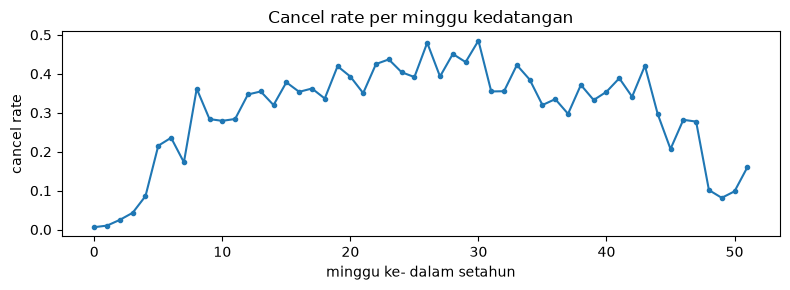

cancel rate 2 minggu awal Januari 0.017, 2 minggu akhir Desember 0.148, awal Juli 0.431


,linear (std),sin/cos
1 Jan vs 31 Des,3.883,0.022
1 Jan vs 1 Jul,1.931,2.000


In [7]:
week = (E['arrival_dayofyear'] // 7).clip(upper=51)
rate = pd.Series(y).groupby(week.to_numpy()).mean()

plt.figure(figsize=(8, 3))
plt.plot(rate.index, rate.values, marker='o', ms=3)
plt.xlabel('minggu ke- dalam setahun'); plt.ylabel('cancel rate'); plt.title('Cancel rate per minggu kedatangan')
plt.tight_layout(); plt.show()

doy = E['arrival_dayofyear']
awal, akhir, tengah = y[doy <= 14].mean(), y[doy >= 352].mean(), y[(doy >= 175) & (doy <= 189)].mean()
print(f'cancel rate 2 minggu awal Januari {awal:.3f}, 2 minggu akhir Desember {akhir:.3f}, awal Juli {tengah:.3f}')

# jarak 1 Januari ke 31 Desember dan ke 1 Juli, linear (dalam std) vs sin/cos
std = doy.std()
cyc = lambda a, b: np.hypot(np.sin(2*np.pi*a/365.25) - np.sin(2*np.pi*b/365.25), np.cos(2*np.pi*a/365.25) - np.cos(2*np.pi*b/365.25))
pd.DataFrame({'linear (std)': [abs(1 - 365) / std, abs(1 - 182) / std], 'sin/cos': [cyc(1, 365), cyc(1, 182)]},
             index=['1 Jan vs 31 Des', '1 Jan vs 1 Jul']).round(3)

- Data menunjukkan cancel rate awal Januari (1,7%) dan akhir Desember (14,8%) sama-sama jauh di bawah awal Juli (43,1%), jadi pergantian tahun itu satu musim sepi yang sama.
- Dengan arrival_dayofyear biasa, 1 Januari dan 31 Desember malah jadi pasangan paling jauh (3,88 std), lebih jauh dari 1 Januari ke 1 Juli (1,93 std). Dengan sin/cos jaraknya tinggal 0,02.
- Jadi arrival_dayofyear diganti doy_sin dan doy_cos, supaya KNN melihat tanggal di sekitar pergantian tahun sebagai tetangga.

## 3.2 Tanggal Booking

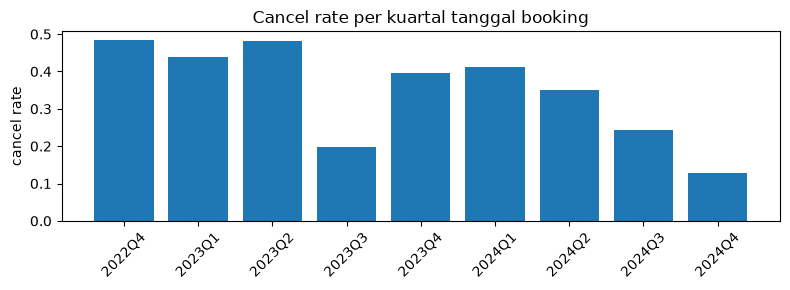

          mean  size
quarter             
2022Q4   0.483   120
2023Q1   0.440   275
2023Q2   0.481   574
2023Q3   0.198  3236
2023Q4   0.396  3774
2024Q1   0.412  7851
2024Q2   0.349  4461
2024Q3   0.243  3940
2024Q4   0.128  1958


days_before_arrival    0.431
arrival_index          0.171
booking_index         -0.094
dtype: float64

In [8]:
booking_date = pd.Timestamp('2023-01-01') + pd.to_timedelta(E['booking_index'], unit='D')
quarter = booking_date.dt.to_period('Q').astype(str)
by_q = pd.DataFrame({'quarter': quarter, 'batal': y}).groupby('quarter')['batal'].agg(['mean', 'size'])
by_q = by_q[by_q['size'] >= 100]

plt.figure(figsize=(8, 3))
plt.bar(by_q.index, by_q['mean'])
plt.xticks(rotation=45); plt.ylabel('cancel rate'); plt.title('Cancel rate per kuartal tanggal booking')
plt.tight_layout(); plt.show()

# korelasi feature tanggal dengan target
corr = pd.Series({c: np.corrcoef(E[c].fillna(E[c].median()), y)[0, 1]
                  for c in ['days_before_arrival', 'arrival_index', 'booking_index']})
print(by_q.round(3).to_string())
corr.round(3)

- Cancel rate berubah jelas tergantung kapan booking dibuat: booking di 2024Q1 batal 41,2%, sedangkan 2024Q4 cuma 12,8% dan 2023Q3 19,8%.
- booking_index = arrival_index - days_before_arrival. Korelasinya dengan target (-0,094) beda arah dengan arrival_index (0,171), jadi informasinya bukan duplikat.
- Di KNN, dua booking yang dibuat di hari yang sama bisa kelihatan jauh karena tanggal datang dan lead time-nya beda, jadi tanggal booking perlu jadi kolom sendiri.

## Preprocessor KNN

In [9]:
class KNNPrep:

    def __init__(self, cfg):
        self.cfg = dict(cfg)

    # daftar feature: encoding siklus ganti arrival_dayofyear, booking_index ikut ditambah
    def features(self):
        feats = list(Settings.BASE_FEATURES)
        if self.cfg.get('cyclic'):
            i = feats.index('arrival_dayofyear')
            feats[i:i + 1] = ['doy_sin', 'doy_cos']
        if self.cfg.get('booking'):
            feats.append('booking_index')
        return feats

    # fit statistik dari data train aja: median, center, spread, modus, kategori, cancel rate
    def fit(self, df):
        F = engineer(df)
        y_fit = df[TARGET].to_numpy()
        self.stats_ = {}
        for f in self.features():
            if f in CAT_COLS:
                mode = F[f].mode()[0]
                vals = F[f].fillna(mode)
                if self.cfg.get('vdm'):
                    # VDM: kategori diganti cancel rate-nya, dibagi rentang rate
                    rate = pd.Series(y_fit).groupby(vals.to_numpy()).mean()
                    self.stats_[f] = ('vdm', mode, rate, (rate.max() - rate.min()) or 1.0, y_fit.mean())
                else:
                    self.stats_[f] = ('onehot', mode, sorted(vals.unique()))
                continue
            x = F[f].astype(float)
            med = x.median()
            xf = x.fillna(med)
            if self.cfg.get('scaler') == 'minmax':
                center, spread = xf.min(), xf.max() - xf.min()
            else:
                center, spread = xf.mean(), xf.std()
            self.stats_[f] = ('num', med, center, spread if spread > 0 else 1.0)
        return self

    # pakai statistik yang udah di-fit, hasilnya array float32
    def transform(self, df):
        F = engineer(df)
        cols = []
        for f in self.features():
            st = self.stats_[f]
            if st[0] == 'vdm':
                _, mode, rate, span, prior = st
                cols.append((F[f].fillna(mode).map(rate).fillna(prior) / span).to_numpy())
            elif st[0] == 'onehot':
                # one-hot 0,5: kategori beda jaraknya 0,5 + 0,5 = 1
                _, mode, levels = st
                cols += [((F[f].fillna(mode) == lv) * 0.5).to_numpy() for lv in levels]
            else:
                _, med, center, spread = st
                cols.append(((F[f].astype(float).fillna(med) - center) / spread).to_numpy())
        return np.column_stack(cols).astype(np.float32)

KNNPrep(CFG.FINAL_CFG).fit(train).transform(test_raw)[:3]

array([[ 1.5764682 ,  0.5678157 , -0.77298456, -0.72974396,  0.        ,
         0.        ,  0.        ,  0.5       ,  0.        , -0.6472166 ,
        -1.022812  , -1.1202583 , -0.17304398, -0.36364627],
       [ 1.2560894 ,  0.18871602, -0.77298456,  0.52626586,  0.        ,
         0.        ,  0.        ,  0.        ,  0.5       ,  0.5217836 ,
        -1.3632822 , -0.0125539 , -0.17304398, -0.5454374 ],
       [ 0.47294146, -0.08309131,  0.5003557 ,  0.3690438 ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.5       ,  1.28352   ,
        -0.870035  , -0.0125539 , -0.17304398, -0.34966233]],
      dtype=float32)

# Modeling dan Validation

## 4.1 KNN from Scratch

In [10]:
class KNN:

    def __init__(self, k=31, p=1, kernel='inv', batch_size=Settings.BATCH):
        self.k, self.p, self.kernel, self.batch_size = k, p, kernel, batch_size

    # lazy learner, cukup simpan data train
    def fit(self, X, y):
        self.X_, self.y_ = np.asarray(X, dtype=np.float32), np.asarray(y).astype(int)
        return self

    # k neighbor terdekat pakai jarak Minkowski p, urut dari yang paling dekat
    def kneighbors(self, Q):
        Q = np.asarray(Q, dtype=np.float32)
        all_d, all_i = [], []
        for s in range(0, len(Q), self.batch_size):
            q = Q[s:s + self.batch_size]
            D = np.zeros((len(q), len(self.X_)), np.float32)
            for j in range(self.X_.shape[1]):
                diff = np.abs(q[:, j, None] - self.X_[None, :, j])
                D += diff if self.p == 1 else diff ** self.p
            idx = np.argpartition(D, self.k - 1, axis=1)[:, :self.k]
            d = np.take_along_axis(D, idx, 1)
            order = np.argsort(d, axis=1, kind='stable')
            all_i.append(np.take_along_axis(idx, order, 1))
            all_d.append(np.take_along_axis(d, order, 1) ** (1 / self.p))
        return np.vstack(all_d), np.vstack(all_i)

    # probabilitas batal dari vote neighbor, weight 1/d atau 1/d^2
    def predict_proba(self, Q):
        d, idx = self.kneighbors(Q)
        w = 1.0 / (d ** 2 + 1e-6) if self.kernel == 'inv2' else 1.0 / (d + 1e-6)
        return (w * self.y_[idx]).sum(1) / w.sum(1)

    # label 0/1 berdasarkan threshold
    def predict(self, Q, threshold=0.5):
        return (self.predict_proba(Q) >= threshold).astype(int)

toy = KNN(k=3, p=1).fit([[0, 0], [0, 1], [5, 5], [5, 6]], [0, 0, 1, 1])
toy.kneighbors([[4, 5]]), toy.predict_proba([[4, 5]])

((array([[1., 2., 8.]], dtype=float32), array([[2, 3, 1]])),
 array([0.92307687]))

## 4.2 Skema Validasi

In [11]:
CACHE = {}

def make_knn(cfg):
    return KNN(k=Settings.K, p=cfg.get('p', 1), kernel=cfg.get('kernel', 'inv'))

# OOF 5 fold buat satu cfg dan satu seed, hasilnya (threshold, Macro F1, proba)
def oof_score(cfg, seed=CFG.SEED):
    key = (repr(sorted(cfg.items())), seed)
    if key not in CACHE:
        oof = np.zeros(len(y))
        for tr, va in stratified_kfold(y, CFG.N_FOLDS, seed):
            prep = KNNPrep(cfg).fit(train.iloc[tr])
            knn = make_knn(cfg).fit(prep.transform(train.iloc[tr]), y[tr])
            oof[va] = knn.predict_proba(prep.transform(train.iloc[va]))
        CACHE[key] = (*best_threshold(y, oof), oof)
    return CACHE[key]

t, s, _ = oof_score(CFG.BASE_CFG)
print(f'baseline (z-score, Manhattan, 1/d, k {Settings.K}): OOF {s:.4f}, threshold {t}')

baseline (z-score, Manhattan, 1/d, k 31): OOF 0.8400, threshold 0.48


## 4.3 Voting Kernel 1/d²

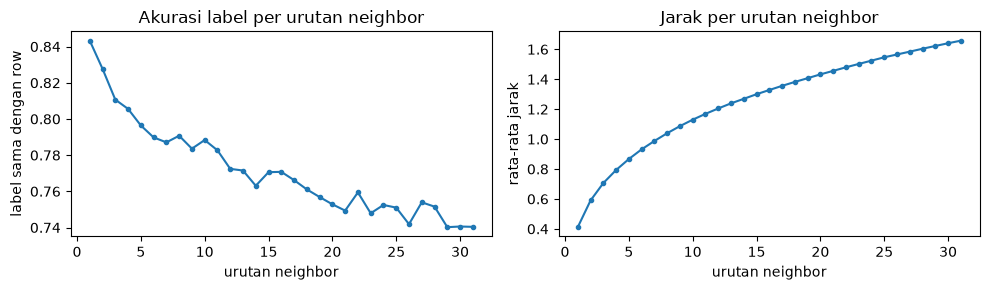

,label sama (neighbor 1),label sama (neighbor 31),"weight n1/nK, 1/d","weight n1/nK, 1/d^2"
0,0.843,0.74,5.046,25.457001


In [12]:
# pakai cfg langkah sebelum kernel
knn_cfg = {k: v for k, v in CFG.FINAL_CFG.items() if k != 'kernel'}
tr, va = stratified_kfold(y, CFG.N_FOLDS, CFG.SEED)[0]
prep = KNNPrep(knn_cfg).fit(train.iloc[tr])
d, idx = make_knn(knn_cfg).fit(prep.transform(train.iloc[tr]), y[tr]).kneighbors(prep.transform(train.iloc[va]))
agree = (y[tr][idx] == y[va][:, None]).mean(0)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(range(1, Settings.K + 1), agree, marker='o', ms=3)
ax[0].set_xlabel('urutan neighbor'); ax[0].set_ylabel('label sama dengan row'); ax[0].set_title('Akurasi label per urutan neighbor')
ax[1].plot(range(1, Settings.K + 1), d.mean(0), marker='o', ms=3)
ax[1].set_xlabel('urutan neighbor'); ax[1].set_ylabel('rata-rata jarak'); ax[1].set_title('Jarak per urutan neighbor')
plt.tight_layout(); plt.show()

ratio = lambda w: np.median(w[:, 0] / w[:, -1])
pd.DataFrame({'label sama (neighbor 1)': [agree[0]], f'label sama (neighbor {Settings.K})': [agree[-1]],
              'weight n1/nK, 1/d': [ratio(1 / (d + 1e-6))], 'weight n1/nK, 1/d^2': [ratio(1 / (d ** 2 + 1e-6))]}).round(3)

- Neighbor terdekat labelnya sama dengan row yang diprediksi 84,3%, neighbor ke-31 cuma 74,0%, jadi makin jauh neighbor-nya makin kurang bisa dipercaya.
- Dengan 1/d, neighbor pertama cuma sekitar 5,0x lebih berpengaruh dari neighbor ke-31, dengan 1/d² sekitar 25,5x. Neighbor jauh tetap ikut vote tapi suaranya kecil.
- Karena itu k bisa dibikin besar (31) tanpa bikin prediksi kabur.

## 4.4 Validasi Tiap Langkah

In [13]:
rows, cfg = [], dict(CFG.BASE_CFG)
t, s, _ = oof_score(cfg)
rows.append({'langkah': 'baseline', 'OOF Macro F1': s, 'threshold': t})
for name, key, value in CFG.STEPS:
    cfg = {**cfg, key: value}
    t, s, _ = oof_score(cfg)
    rows.append({'langkah': f'+ {name}', 'OOF Macro F1': s, 'threshold': t})
steps = pd.DataFrame(rows).set_index('langkah')
steps['selisih'] = steps['OOF Macro F1'].diff()

KNN_THRESHOLD, _, oof_knn = oof_score(CFG.FINAL_CFG)
steps.round(4)

,OOF Macro F1,threshold,selisih
langkah,,,
baseline,0.8400,0.48,NaN
+ Encoding Siklus Tanggal Kedatangan,0.8398,0.47,-0.0002
+ Tanggal Booking,0.8416,0.45,0.0018
+ Voting Kernel 1/d²,0.8438,0.50,0.0022


- Encoding siklus sendirian belum menaikkan OOF (0,8400 ke 0,8398, masih noise). Di pencarian kombinasi, siklus + booking_index (0,8435) lebih baik dari booking_index saja (0,8422), jadi langkah ini dipakai bareng booking_index.
- booking_index menaikkan OOF +0,0018 (0,8398 ke 0,8416).
- Kernel 1/d² menaikkan OOF +0,0022 (0,8416 ke 0,8438).

## 4.5 Cek dengan Pembagian Fold Lain

In [14]:
rows = []
for seed in CFG.CHECK_SEEDS:
    rows.append({'seed': seed, 'baseline': oof_score(CFG.BASE_CFG, seed)[1], CFG.EXP_NAME: oof_score(CFG.FINAL_CFG, seed)[1]})
seeds = pd.DataFrame(rows).set_index('seed')
seeds['selisih'] = seeds[CFG.EXP_NAME] - seeds['baseline']
print(CFG.EXP_NAME, 'unggul di', int((seeds['selisih'] > 0).sum()), 'dari', len(seeds), 'seed')
print(seeds.mean().round(4).to_string())
seeds.round(4)

knn_cyclic_booking unggul di 5 dari 5 seed
baseline              0.8412
knn_cyclic_booking    0.8450
selisih               0.0038


,baseline,knn_cyclic_booking,selisih
seed,,,
1,0.8412,0.8461,0.0049
2,0.8413,0.8452,0.0039
3,0.8394,0.8433,0.0039
4,0.8431,0.8451,0.0020
5,0.8411,0.8453,0.0042


# Error Analysis

## Confusion Matrix

In [15]:
pred = (oof_knn >= KNN_THRESHOLD).astype(int)
print('confusion matrix [[TN, FP], [FN, TP]]')
print(confusion_matrix(y, pred))
print('F1 kelas 0, kelas 1', f1_per_class(y, pred).round(4))

confusion matrix [[TN, FP], [FN, TP]]
[[16763  1602]
 [ 2101  6843]]
F1 kelas 0, kelas 1 [0.9005 0.787 ]


## Kesalahan per Kelompok

In [16]:
def error_by(column, bins=None):
    values = train[column] if bins is None else pd.qcut(train[column], bins, duplicates='drop')
    frame = pd.DataFrame({column: values, 'error': pred != y})
    return frame.groupby(column, observed=True, dropna=False)['error'].agg(['mean', 'size']).round(3)

error_by('booking_channel')

,mean,size
booking_channel,,
Airline,0.216,88
Complimentary,0.007,300
Corporate,0.088,1512
Offline Agent,0.071,7902
Online Travel Agent,0.171,17507


In [17]:
error_by('days_before_arrival', bins=5)

,mean,size
days_before_arrival,,
"(-0.001, 11.0]",0.090,5286
"(11.0, 39.0]",0.143,5332
"(39.0, 80.0]",0.153,5186
"(80.0, 151.0]",0.184,5180
"(151.0, 448.0]",0.089,5205
NaN,0.228,1120


In [18]:
error_by('special_requests')

,mean,size
special_requests,,
0.0,0.143,12678
1.0,0.150,8323
2.0,0.076,3246
3.0,0.006,496
4.0,0.000,60
5.0,0.000,7
NaN,0.158,2499


## Proposed Improvements

- Kombinasi siklus + booking_index + kernel 1/d² unggul di 5 dari 5 seed, rata-rata 0,8450 vs baseline 0,8412 (+0,0038).
- Seed 4 kenaikannya paling kecil (+0,0020), jadi kombinasi ini sedikit kurang stabil dibanding knn_cyclic_booking_minkowski yang ditambah p 0,75.
- Saran: tambah p 0,75, karena di knn_cyclic_booking_minkowski langkah ini naik +0,0014.
- Saran: coba scaling min-max sebagai pengganti z-score di kombinasi ini.

# Submission

## 6.1 Training Final

In [19]:
prep_final = KNNPrep(CFG.FINAL_CFG).fit(train)
knn_final = make_knn(CFG.FINAL_CFG).fit(prep_final.transform(train), y)
print('cfg', CFG.FINAL_CFG, ' threshold', KNN_THRESHOLD)

cfg {'cyclic': True, 'booking': True, 'kernel': 'inv2'}  threshold 0.5


## 6.2 Save dan Load Model

In [20]:
save_model({'preprocessor': prep_final, 'model': knn_final, 'threshold': KNN_THRESHOLD}, CFG.MODEL_PATH)
bundle = load_model(CFG.MODEL_PATH)
print('model tersimpan di', CFG.MODEL_PATH)

model tersimpan di knn_cyclic_booking.pkl


## 6.3 Prediksi dan File Submission

In [21]:
X_test = bundle['preprocessor'].transform(test_raw)
test_pred = bundle['model'].predict(X_test, threshold=bundle['threshold'])

submission = pd.DataFrame({'id': test_raw['id'], 'is_canceled': test_pred})
submission.to_csv(CFG.SUB_PATH, index=False)
submission['is_canceled'].value_counts(normalize=True).round(4)

is_canceled
0    0.6996
1    0.3004
Name: proportion, dtype: float64